# **UNSW-NB15 Dataset Exploratory & Processing**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pyod.models.ecod import ECOD
from pyod.models.iforest import IForest
from sklearn.metrics import average_precision_score

df = pd.read_csv('/Users/han./Desktop/CS5344/data/raw/UNSW-NB15_train.csv')
df.shape

(50000, 43)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 43 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   dur                50000 non-null  float64
 1   spkts              50000 non-null  int64  
 2   dpkts              50000 non-null  int64  
 3   sbytes             50000 non-null  int64  
 4   dbytes             50000 non-null  int64  
 5   rate               50000 non-null  float64
 6   sttl               50000 non-null  int64  
 7   dttl               50000 non-null  int64  
 8   sload              50000 non-null  float64
 9   dload              50000 non-null  float64
 10  sloss              50000 non-null  int64  
 11  dloss              50000 non-null  int64  
 12  sinpkt             50000 non-null  float64
 13  dinpkt             50000 non-null  float64
 14  sjit               50000 non-null  float64
 15  djit               50000 non-null  float64
 16  swin               50000 non-null

---
**Class Imbalance**

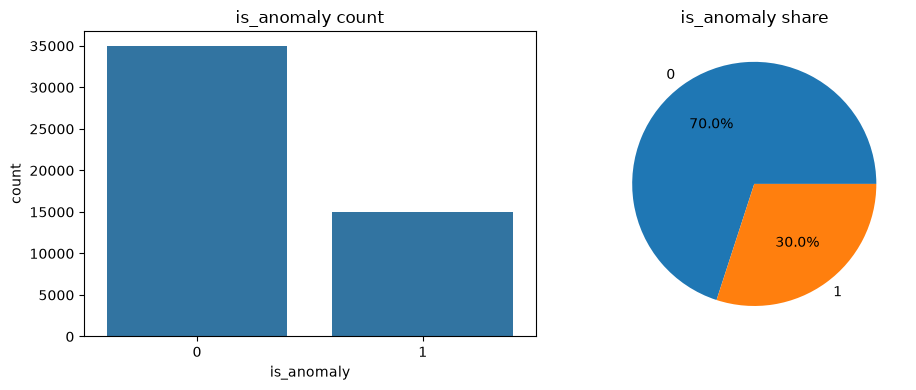

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(x='is_anomaly', data=df, ax=axes[0])
axes[0].set_title('is_anomaly count')
df['is_anomaly'].value_counts().plot.pie(autopct='%1.1f%%', ax=axes[1])
axes[1].set_title('is_anomaly share')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

----
**Analysis on Categorical Features**

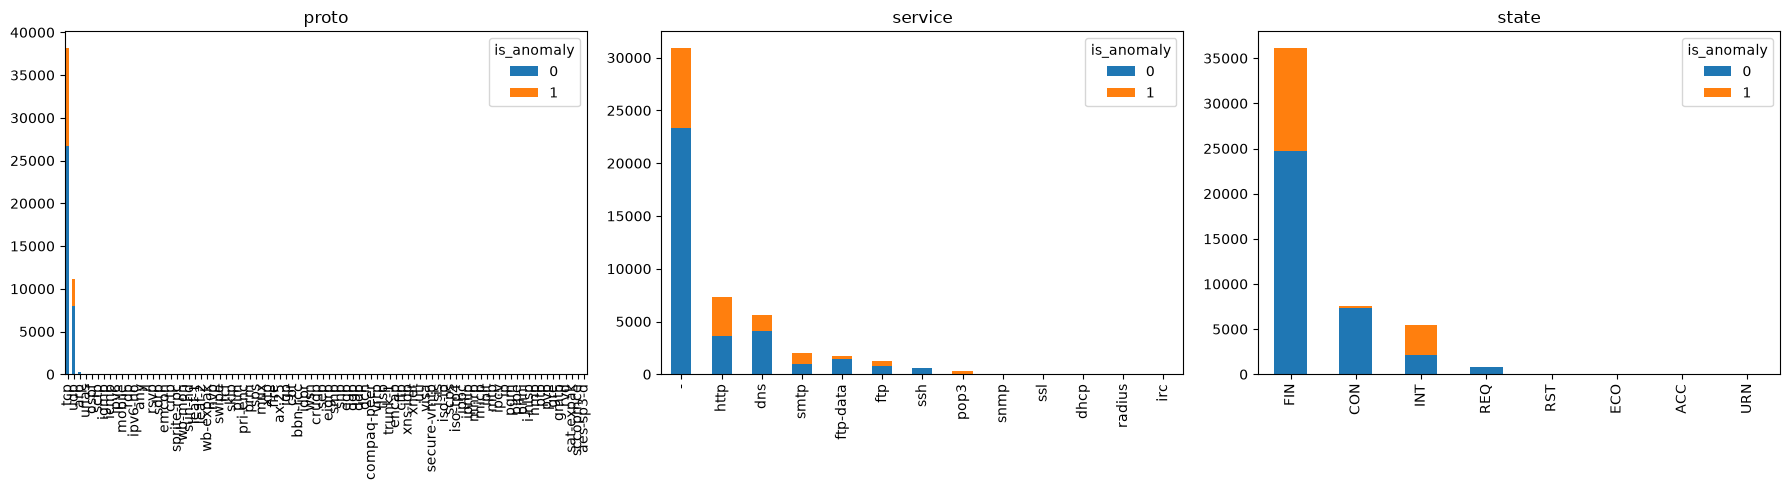

--- proto --- n_unique=86
is_anomaly      0      1  total
proto                          
tcp         26678  11531  38209
udp          7965   3218  11183
arp           303      0    303
unas            0     73     73
ospf           31     33     64
sctp            0     18     18
igmp           17      0     17
icmp            6      0      6
ipv6            0      5      5
mobile          0      4      4

--- service --- n_unique=13
is_anomaly      0     1  total
service                       
-           23380  7569  30949
http         3665  3702   7367
dns          4126  1530   5656
smtp          933  1087   2020
ftp-data     1478   230   1708
ftp           818   479   1297
ssh           596     0    596
pop3            1   347    348
snmp            1    20     21
ssl             0    16     16

--- state --- n_unique=8
is_anomaly      0      1  total
state                          
FIN         24688  11479  36167
CON          7381    156   7537
INT          2116   3335   5451
REQ

In [4]:
cat_cols = ['proto', 'service', 'state']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, cat_cols):
    ct = pd.crosstab(df[col], df['is_anomaly'])
    ct['total'] = ct.sum(axis=1)
    ct = ct.sort_values('total', ascending=False).drop(columns='total')
    ct.plot(kind='bar', stacked=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

for col in cat_cols:
    print(f"--- {col} --- n_unique={df[col].nunique()}")
    ct = pd.crosstab(df[col], df['is_anomaly'])
    ct['total'] = ct.sum(axis=1)
    print(ct.sort_values('total', ascending=False).head(10))
    print()

- No single categorical column separates normal from attack as cleanly as NSL's `flag` does. `proto`, `service` and `state` all mix both classes in their dominant categories, so the generator needs to preserve full conditional distributions `P(cat|normal)`, not just pick the top category.
- `proto` (86 unique) — normal traffic is 76.2% `tcp`, 22.8% `udp`, with a long tail of rare protocols (`arp`, `igmp`, `icmp`, `ospf`) that are almost entirely normal-only in this sample. Attacks are dominated by `tcp`/`udp` too, plus a handful of protocols (`unas`, `sctp`, `ipv6`, `mobile`, `rdp`) that only ever appear in attack rows.
- `service` (13 unique) — `-` (no identified application-layer service) is the dominant category for both classes (66.8% of normal, but also 7569/30949 of all `-` rows are attacks), so it's a weak signal on its own. `ssh` is normal-only in this sample and `pop3` is almost entirely attack-only — rare categories carry more label information than the dominant one.
- `state` (8 unique) — `FIN` dominates normal (70.5%) but is also the majority state for attacks (11479 attack rows), so it's not a clean fingerprint. `CON` is the cleanest normal indicator (7381 normal vs. 156 attack), while `INT` skews attack-heavy (2116 normal vs. 3335 attack).
- Practical takeaway: sample `(proto, service, state)` jointly from the empirical normal-only distribution rather than independently per-column — rare-but-informative categories and their co-occurrence with numeric features (e.g. `service=ftp` with `ct_ftp_cmd`) matter more here than in NSL.

---

**Check Which Features are Near Constant and Which are Heavily Skewed**

In [5]:
from scipy.stats import skew

normal_df = df[df['is_anomaly'] == 0]
numeric_cols = [c for c in df.select_dtypes(include='number').columns if c != 'is_anomaly']

zero_pct = normal_df[numeric_cols].eq(0).mean().sort_values(ascending=False)
print("Zero-inflated features (zero_pct > 0.5):")
print(zero_pct[zero_pct > 0.5])
print()

skew_vals = normal_df[numeric_cols].apply(lambda x: skew(x)).sort_values(ascending=False)
print("Top 15 most skewed features:")
print(skew_vals.head(15))

Zero-inflated features (zero_pct > 0.5):
is_sm_ips_ports      0.992971
is_ftp_login         0.984600
ct_ftp_cmd           0.984571
response_body_len    0.905714
ct_flw_http_mthd     0.897029
trans_depth          0.897029
ct_state_ttl         0.652714
dtype: float64

Top 15 most skewed features:
ct_dst_sport_ltm     80.001850
djit                 25.796296
dinpkt               23.824382
sjit                 20.040545
response_body_len    12.698793
sload                12.302448
is_sm_ips_ports      11.801843
sinpkt               10.992768
synack               10.716770
ackdat               10.535563
sbytes               10.278704
dur                  10.209387
rate                  8.919348
ct_flw_http_mthd      8.835266
is_ftp_login          7.908720
dtype: float64


For each numeric feature, apply the same procedure — there is no A/B/C split by feature name:

1. **Compute `p = P(feature == 0)`** on the normal-only subset
2. **Model the zero/nonzero split** as a Bernoulli(`p`)
3. **Fit a distribution only on the nonzero values** (apply `log1p` first if skewed, then fit e.g. log-normal)
4. **To generate a synthetic value:** flip the Bernoulli(`p`) → if "zero," output 0; if "nonzero," sample from the fitted nonzero distribution (then inverse-transform if log1p was applied)

**Edge case:** if a feature has very few nonzero values (e.g. <20), don't fit a parametric distribution on them — resample directly from the empirical nonzero values instead.

**Why one rule, no cutoff:**
- Zero-percentage is a continuous spectrum here too (99.3% → 90% → 65% → near-0), not naturally clustered — any manual cutoff is arbitrary
- One consistent rule generalizes automatically: `is_sm_ips_ports` (p=0.993) naturally collapses to "almost always 0"; `ct_state_ttl` (p=0.653) just gets a smaller Bernoulli p
- Keeps the pipeline transferable across NSL-KDD and UNSW-NB15 without re-deciding thresholds per dataset

**What's actually zero-inflated in UNSW (normal-only):** `is_sm_ips_ports` (99.3%), `is_ftp_login`/`ct_ftp_cmd` (98.5%, near-identical — see the correlation section), `response_body_len`/`ct_flw_http_mthd`/`trans_depth` (~90%, all http-only fields, zero for every non-http connection), `ct_state_ttl` (65.3%). This is a different set from NSL's zero-inflated features but the same *shape* of problem — mostly connection-type indicator features that are legitimately zero outside their triggering context (ftp/http), not noise.

**What's most skewed:** `ct_dst_sport_ltm` (skew ≈ 80, driven by a few extreme outlier rows), then jitter/inter-packet-time features (`djit`, `dinpkt`, `sjit`, `sinpkt`) and byte/rate features (`sload`, `sbytes`, `rate`, `dur`) — all classic heavy right tails from a small number of long-lived or bursty connections.

---

**Bounded Rate Features**

Bounded [0,1] columns (by value range): ['is_sm_ips_ports']

is_sm_ips_ports: zero=99.3% one=0.7% mid=-0.0% n_unique=2


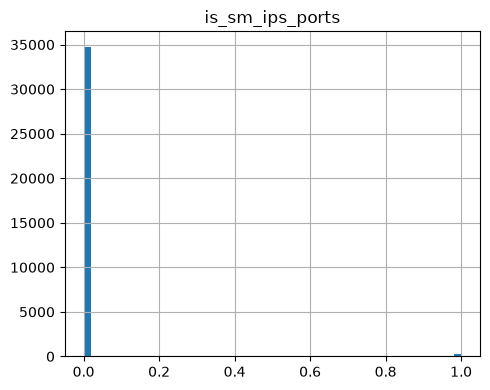

In [6]:
# NSL detects "rate" columns by name substring, which works there because every
# *_rate column happens to be a [0,1] proportion. UNSW's only column literally
# named 'rate' is a throughput value (packets/sec), NOT bounded to [0,1] - so
# detect bounded features by actual value range instead of by name.
mins = normal_df[numeric_cols].min()
maxs = normal_df[numeric_cols].max()
bounded_cols = [c for c in numeric_cols if mins[c] >= 0 and maxs[c] <= 1]
print("Bounded [0,1] columns (by value range):", bounded_cols)
print()

for col in bounded_cols:
    zero_pct = (normal_df[col] == 0).mean()
    one_pct = (normal_df[col] == 1).mean()
    mid_pct = 1 - zero_pct - one_pct
    print(f"{col}: zero={zero_pct:.1%} one={one_pct:.1%} mid={mid_pct:.1%} n_unique={normal_df[col].nunique()}")

if bounded_cols:
    fig, axes = plt.subplots(1, len(bounded_cols), figsize=(5 * len(bounded_cols), 4), squeeze=False)
    for ax, col in zip(axes[0], bounded_cols):
        normal_df[col].hist(bins=50, ax=ax)
        ax.set_title(col)
    plt.tight_layout()
    plt.show()

- UNSW behaves differently from NSL here: checking by actual value range (not name) turns up exactly **one** bounded [0,1] column, `is_sm_ips_ports` — and it's a binary indicator flag (99.3% zero, 0.7% one, effectively no in-between mass), not a continuous proportion.
- UNSW has no `*_rate`-style continuous features that live genuinely inside [0,1] the way NSL's `serror_rate`/`same_srv_rate`/etc. do. The column named `rate` is unbounded (packets/sec throughput, already covered in the skew list above).
- Consequence: the 3-part zero/one/in-between generative model designed for NSL's rate columns isn't needed for UNSW's numeric features — `is_sm_ips_ports` is simpler than that (near-constant, so the plain Bernoulli(p) rule from the zero-inflation section already covers it). This section of the pipeline should be config-driven per dataset: detect candidate bounded columns by range at fit time, and only apply the 3-part model to whichever columns actually qualify — for UNSW that set is empty in practice.

---

**Feature Correlation**

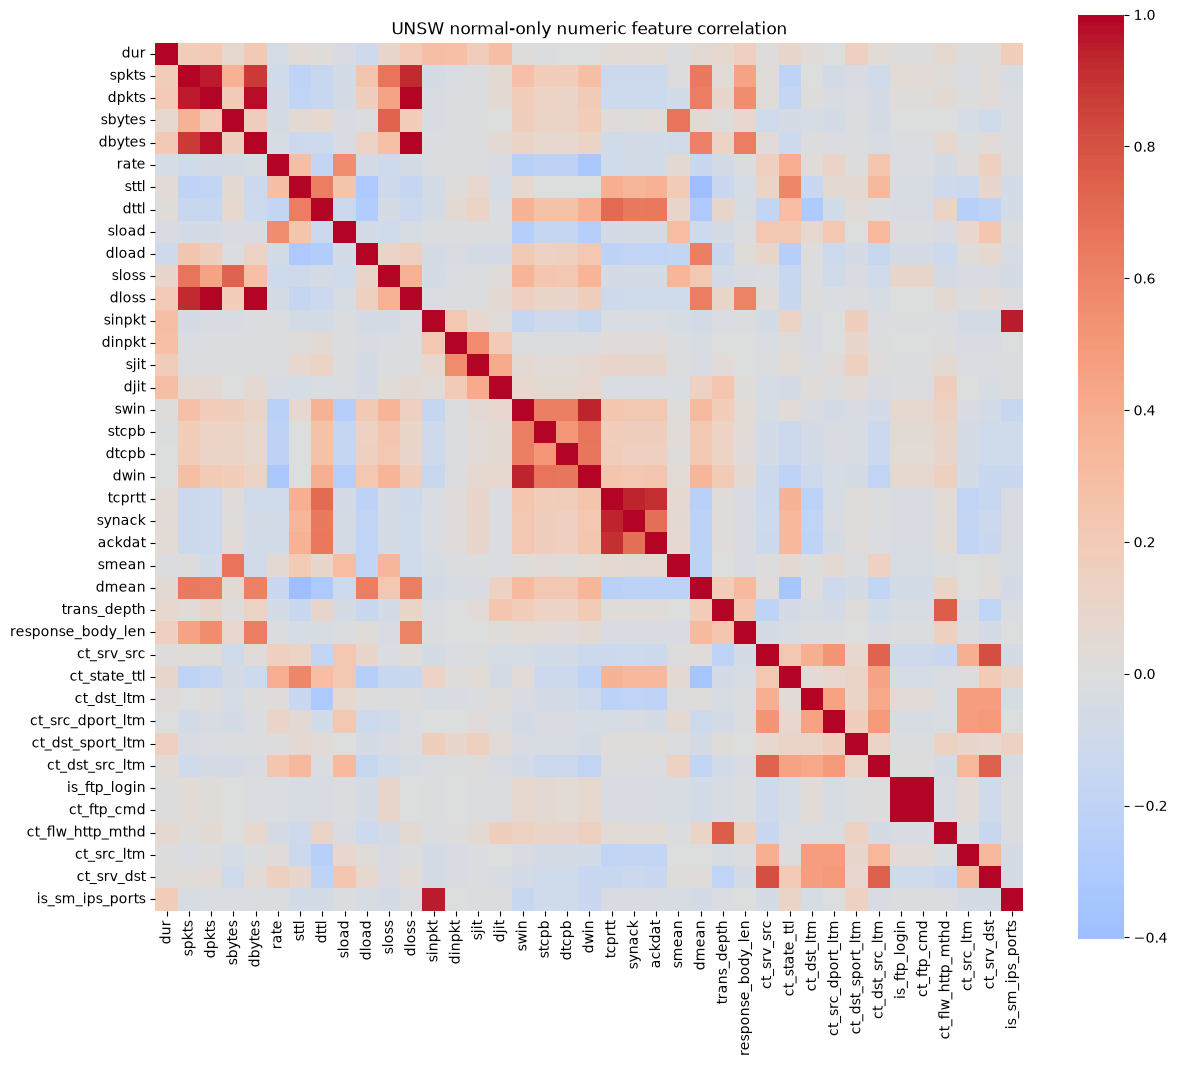

Top 15 positive pairs:
is_ftp_login     ct_ftp_cmd         0.999064
ct_ftp_cmd       is_ftp_login       0.999064
dpkts            dloss              0.993874
dloss            dpkts              0.993874
                 dbytes             0.992466
dbytes           dloss              0.992466
dpkts            dbytes             0.974194
dbytes           dpkts              0.974194
dpkts            spkts              0.953400
spkts            dpkts              0.953400
is_sm_ips_ports  sinpkt             0.952398
sinpkt           is_sm_ips_ports    0.952398
dwin             swin               0.944191
swin             dwin               0.944191
synack           tcprtt             0.934395
dtype: float64

Top 10 most negative pairs:
dmean         dttl           -0.311986
dttl          dmean          -0.311986
dload         sttl           -0.316232
sttl          dload          -0.316232
rate          dwin           -0.325054
dwin          rate           -0.325054
ct_state_ttl  dmean     

In [7]:
corr_matrix = normal_df[numeric_cols].corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, square=True)
plt.title('UNSW normal-only numeric feature correlation')
plt.show()

corr_pairs = corr_matrix.unstack()
corr_pairs = corr_pairs[corr_pairs < 1.0]
corr_pairs = corr_pairs.sort_values(ascending=False)
corr_pairs = corr_pairs[~corr_pairs.index.duplicated()]
print("Top 15 positive pairs:")
print(corr_pairs.head(15))
print()
print("Top 10 most negative pairs:")
print(corr_pairs.tail(10))

UNSW's clusters are different from NSL's (no `root/compromise` or `error_rate` family here — UNSW has no such columns), but the same kind of near-deterministic redundancy shows up:

**1. "FTP login" cluster (~0.999 correlation)**
`is_ftp_login` ↔ `ct_ftp_cmd` — essentially the same signal encoded twice (a 0/1 flag and a count that's 0 or 1 in this data). Sampling them independently would near-certainly produce an inconsistent row (e.g. login flag on, command count off).

**2. "Destination traffic volume" cluster (0.87–0.99)**
`dpkts` ↔ `dloss` (0.994), `dloss` ↔ `dbytes` (0.992), `dpkts` ↔ `dbytes` (0.974), `dpkts` ↔ `spkts` (0.953), `dloss` ↔ `spkts` (0.922), `dbytes` ↔ `spkts` (0.877) — packet count, byte count and packet loss on both sides of the connection move together, as expected for flow-level features.

**3. `is_sm_ips_ports` ↔ `sinpkt` (0.952) — likely a small-sample artifact, not a real cluster**
`is_sm_ips_ports` is 1 for only 0.7% of normal rows (~245 out of 35000). A correlation this high on such a small minority group is easy to get from a handful of extreme `sinpkt` values rather than a genuine relationship — worth re-checking on a larger sample before treating it as load-bearing, unlike the other clusters here.

**4. "TCP window" cluster (~0.94)**
`dwin` ↔ `swin` — source/destination TCP window size move together.

**5. "TCP handshake timing" cluster (0.90–0.93)**
`synack` ↔ `tcprtt` (0.934), `tcprtt` ↔ `ackdat` (0.903) — `tcprtt` is close to the sum of `synack` and `ackdat` by construction, so this redundancy is structural, not incidental.

**6. "Service repetition count" cluster (~0.82)**
`ct_srv_src` ↔ `ct_srv_dst` — both count recent connections to the same service, from the source side vs. destination side.

**7. "HTTP depth" cluster (~0.75)**
`ct_flw_http_mthd` ↔ `trans_depth` — both are zero outside http traffic (see the zero-inflation section) and move together when http is present.

**Negative pairs are weaker here than NSL's** (max magnitude ≈ -0.40, vs. NSL's ~-0.75/-0.8): `sttl` is mildly negatively correlated with `dmean` (-0.40), `dload` (-0.32) and `ct_state_ttl` (-0.35); `rate` is mildly negative with `dwin` (-0.33). None of these are strong enough to treat as a hard constraint the way NSL's `same_srv_rate`/`diff_srv_rate` complementary pair was.

**→ Practical implication:** the ftp-login and TCP-timing clusters are near-deterministic and should be sampled as a block (e.g. draw one underlying factor and derive the rest, or use a copula that preserves rank correlation) rather than independently per-column — independent per-feature sampling would silently break these relationships and produce rows that whitening-based detectors (ECOD, IForest) can trivially flag as inconsistent.

---

**Dimensionality View**

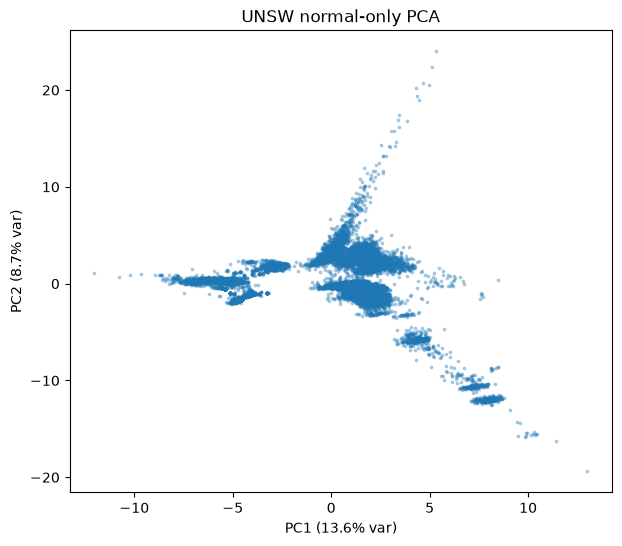

In [8]:
enc_cols = numeric_cols + cat_cols
normal_encoded = pd.get_dummies(normal_df[enc_cols], columns=cat_cols)
X_normal_scaled = StandardScaler().fit_transform(normal_encoded)

pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_normal_scaled)

plt.figure(figsize=(7, 6))
plt.scatter(pca_result[:, 0], pca_result[:, 1], s=3, alpha=0.3)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} var)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} var)')
plt.title('UNSW normal-only PCA')
plt.show()

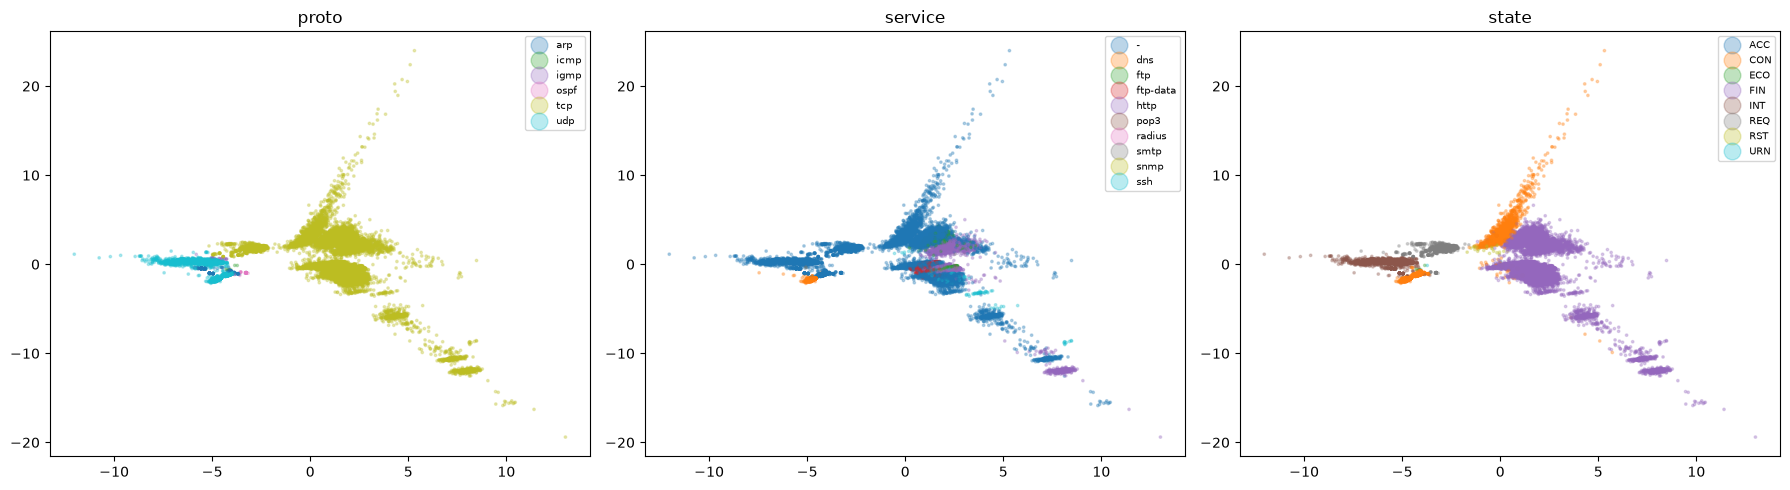

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, choice in zip(axes, cat_cols):
    scatter = ax.scatter(
        pca_result[:, 0], pca_result[:, 1], s=3, alpha=0.3,
        c=normal_df[choice].astype('category').cat.codes, cmap='tab10',
    )
    ax.set_title(choice)
    handles, labels = scatter.legend_elements()
    ax.legend(handles, normal_df[choice].astype('category').cat.categories.tolist(),
               fontsize=7, markerscale=2, loc='best')
plt.tight_layout()
plt.show()

- PC1+PC2 only capture ~22.3% of total variance (13.6% + 8.7%) — much lower than a 2-axis summary would need to be "the whole story." Normal UNSW traffic is genuinely high-dimensional; a 2D PCA-based generator would drop most of the structure. Treat this plot as a sanity check for multi-modality, not as a sufficient generative latent space.
- UNSW is multi-modal, and it's driven primarily by **`proto` × `state`**, not by `service` the way it might be for other datasets. The udp/tcp split from `proto` is nearly identical to the split visible when coloring by `state`: `udp` rows sit almost entirely in the left-hand cluster where `state=CON` (and some `INT`) live, while `tcp` rows spread across the larger central/right arcing structure where `state=FIN` dominates. `proto` and `state` are not independent — they jointly define the visible clusters.
- `service` is comparatively uninformative for the *shape* of the cloud: `-` (no service) covers most of both major clusters, and the handful of named services (`http`, `ftp-data`, `smtp`, `ftp`) only show up as small sub-clusters embedded within the tcp/FIN arcs, not as separate large modes of their own.
- Practical implication: a generator should condition numeric feature sampling on `(proto, state)` jointly at minimum (matching the categorical-features finding above) — collapsing to marginal per-column categorical sampling would blur together numeric distributions that are actually quite different between the udp/CON mode and the tcp/FIN mode.

---

**Fitting ECOD and Isolation Forest**

In [10]:
# diagnostic pass only - uses the FULL labeled data (both classes) since the
# detectors need anomalies to score against. 1 seed x 500 trees here for
# speed; the real grading spec is 10 seeds x 500 trees.
full_encoded = pd.get_dummies(df[enc_cols], columns=cat_cols)
feature_names = full_encoded.columns.tolist()
y_true = df['is_anomaly'].values
X_scaled = StandardScaler().fit_transform(full_encoded)

ecod = ECOD()
ecod.fit(X_scaled)
ecod_scores = ecod.decision_scores_
ecod_auprc = average_precision_score(y_true, ecod_scores)
print(f"ECOD AUPRC: {ecod_auprc:.4f}")

ecod_top = pd.Series(ecod.O[y_true == 1].mean(axis=0), index=feature_names).sort_values(ascending=False)
print("ECOD top 15 features (mean per-feature outlier contribution on true-anomaly rows):")
print(ecod_top.head(15))

ECOD AUPRC: 0.3912
ECOD top 15 features (mean per-feature outlier contribution on true-anomaly rows):
sload         1.955607
dur           1.915490
rate          1.867849
smean         1.822274
dinpkt        1.802139
sinpkt        1.779480
sbytes        1.633444
ackdat        1.630654
tcprtt        1.576397
sjit          1.566750
synack        1.565930
dmean         1.552498
ct_srv_src    1.536033
djit          1.506095
ct_srv_dst    1.486940
dtype: float64


In [11]:
iforest = IForest(n_estimators=500, random_state=42)
iforest.fit(X_scaled)
if_scores = iforest.decision_scores_
if_auprc = average_precision_score(y_true, if_scores)
print(f"IForest AUPRC: {if_auprc:.4f}")

# IForest has no native per-feature score - use correlation between each
# scaled feature and the anomaly score as a proxy for feature importance
if_top = pd.DataFrame(X_scaled, columns=feature_names).corrwith(pd.Series(if_scores)).abs().sort_values(ascending=False)
print("IForest top 15 proxy features (|corr| with anomaly score):")
print(if_top.head(15))

print()
print(f"S = (ECOD_AUPRC + IForest_AUPRC) / 2 = {(ecod_auprc + if_auprc) / 2:.4f}")

IForest AUPRC: 0.3622
IForest top 15 proxy features (|corr| with anomaly score):
state_FIN           0.512138
dwin                0.473498
ct_dst_src_ltm      0.466387
state_INT           0.435241
swin                0.432111
proto_tcp           0.431898
ct_src_dport_ltm    0.430069
ct_dst_ltm          0.418278
ct_dst_sport_ltm    0.414771
proto_udp           0.386874
ct_srv_dst          0.368532
ct_src_ltm          0.363029
service_-           0.352950
ct_srv_src          0.345547
rate                0.325940
dtype: float64

S = (ECOD_AUPRC + IForest_AUPRC) / 2 = 0.3767


**Diagnostic AUPRC (1 seed, single reference fit — not the graded spec):** ECOD = 0.391, IForest = 0.362, S ≈ 0.377. Both detectors do moderately well at separating `A_seen`-type attacks from normal on this training split; the two detectors lean on almost entirely different features to do it.

| Shared by both detectors | ECOD-specific | IForest-specific |
|---|---|---|
| `rate`, `ct_srv_src`, `ct_srv_dst` | `sload`, `dur`, `smean`, `dinpkt`, `sinpkt`, `sbytes`, `ackdat`, `tcprtt`, `sjit`, `synack`, `dmean`, `djit` | `state_FIN`, `dwin`, `ct_dst_src_ltm`, `state_INT`, `swin`, `proto_tcp`, `ct_src_dport_ltm`, `ct_dst_ltm`, `ct_dst_sport_ltm`, `proto_udp`, `ct_src_ltm`, `service_-` |

- **ECOD leans almost entirely on continuous distributional features** — load/byte/timing/jitter columns (`sload`, `dur`, `sbytes`, `sinpkt`/`dinpkt`, `sjit`/`djit`, `synack`/`ackdat`/`tcprtt`). Makes sense: ECOD scores per-dimension tail probability, so it's most sensitive where the normal distribution has a sharp, well-defined shape that anomalies fall outside of.
- **IForest leans almost entirely on the one-hot categorical dummies plus connection-count features** — `state_FIN`/`state_INT`, `proto_tcp`/`proto_udp`, `service_-`, and the `ct_*` family (`ct_dst_src_ltm`, `ct_src_dport_ltm`, `ct_dst_ltm`, `ct_dst_sport_ltm`, `ct_src_ltm`). Isolation Forest splits on whatever creates the shortest isolating partitions, and one-hot categorical splits are cheap, high-leverage splits — consistent with the PCA finding that `proto`/`state` drive the biggest structural clusters.
- Only 3 features matter to both: `rate`, `ct_srv_src`, `ct_srv_dst`.

**→ Final method direction:** because the two fixed detectors respond to almost disjoint feature sets, the synthetic data can't just get the marginal numeric distributions right (for ECOD) OR just get the categorical/count structure right (for IForest) — it needs both to score well on `S`. This reinforces the correlation-section conclusion (preserve the ftp-login/traffic-volume/handshake-timing blocks) and the PCA-section conclusion (condition on `proto`×`state` jointly), rather than treating numeric and categorical generation as separable problems.

---

**Putting it together: a generation sketch for UNSW normal data**

1. Sample `(proto, service, state)` jointly from the empirical normal-only joint distribution (categorical-features + PCA sections both show these are not independent, and `proto`×`state` in particular defines the main modes).
2. For each numeric feature not in a correlated block, apply the Bernoulli(p) + nonzero-distribution rule from the zero-inflation section, independently.
3. For the correlated blocks found in the correlation section — ftp login (`is_ftp_login`/`ct_ftp_cmd`), destination traffic volume (`dpkts`/`dloss`/`dbytes`/`spkts`), TCP window (`dwin`/`swin`), TCP handshake timing (`synack`/`tcprtt`/`ackdat`), service-repetition counts (`ct_srv_src`/`ct_srv_dst`), HTTP depth (`ct_flw_http_mthd`/`trans_depth`) — sample each block jointly rather than column-by-column, so the near-deterministic relationships survive into the synthetic rows.
4. Optionally condition steps 2–3 on the sampled `(proto, state)` mode from step 1, since the numeric distributions plausibly differ between the udp/CON mode and the tcp/FIN mode (not yet verified — would need per-mode zero-inflation/skew/correlation re-checks before committing to this).

**Generative model family comparison, given these findings:**

- **Multivariate Gaussian / GMM** — a single multivariate Gaussian ignores both the zero-inflation (Bernoulli+nonzero shape isn't Gaussian) and the `proto`×`state` multi-modality (only 22.3% of variance in 2 PCs already signals a non-Gaussian, non-low-rank shape). A per-mode GMM (one component per `proto`×`state` combination) could capture the multi-modality, but the rarer combinations (e.g. `arp`, `igmp`, `ospf` protocols) have too few normal rows to fit a stable component.
- **Gaussian / Vine Copula** — separates marginals (fit each feature's own Bernoulli+nonzero-distribution shape, exactly matching the zero-inflation-section methodology) from the dependence structure (captures the correlated blocks from the correlation section via rank correlation, without needing every block to be jointly Gaussian). This lines up best with what was actually found: heterogeneous marginals + a handful of strong, specific pairwise/block dependencies, not one global covariance structure.
- **Conditional VAE** — has the most capacity to jointly model multi-modality, zero-inflation and correlated blocks without hand-specifying which columns belong to which block, but needs enough normal rows per `(proto, state)` stratum to train reliably (some strata here are in the single digits), and is the hardest to satisfy the explainability requirement for — harder to point at a specific mechanism ("why does the model always output `ct_ftp_cmd`≈`is_ftp_login`?") the way a copula's explicit marginal+dependence decomposition allows.

**Working direction:** condition on `(proto, state)` for the categorical/mode structure, use per-feature Bernoulli+nonzero-distribution marginals from the zero-inflation section, and tie the correlated blocks together with a copula (or, more simply, per-block joint empirical resampling) rather than a single global multivariate distribution — this is the same class of design as the NSL notebook's conclusion, and nothing found here contradicts using one shared pipeline across both datasets, just different config (categorical columns, block membership, mode-defining columns) per dataset.